## Name : Sajjad Hussain 
## Assignment : 01


In [330]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [331]:
p_data = pd.read_csv('D:\\CAS_Ai WorkShops\\penguins.csv')
p_data.head(5)

,id,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [332]:
p_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 344 non-null    int64  
 1   species            344 non-null    object 
 2   island             344 non-null    object 
 3   bill_length_mm     342 non-null    float64
 4   bill_depth_mm      342 non-null    float64
 5   flipper_length_mm  342 non-null    float64
 6   body_mass_g        342 non-null    float64
 7   sex                333 non-null    object 
 8   year               344 non-null    int64  
dtypes: float64(4), int64(2), object(3)
memory usage: 24.3+ KB


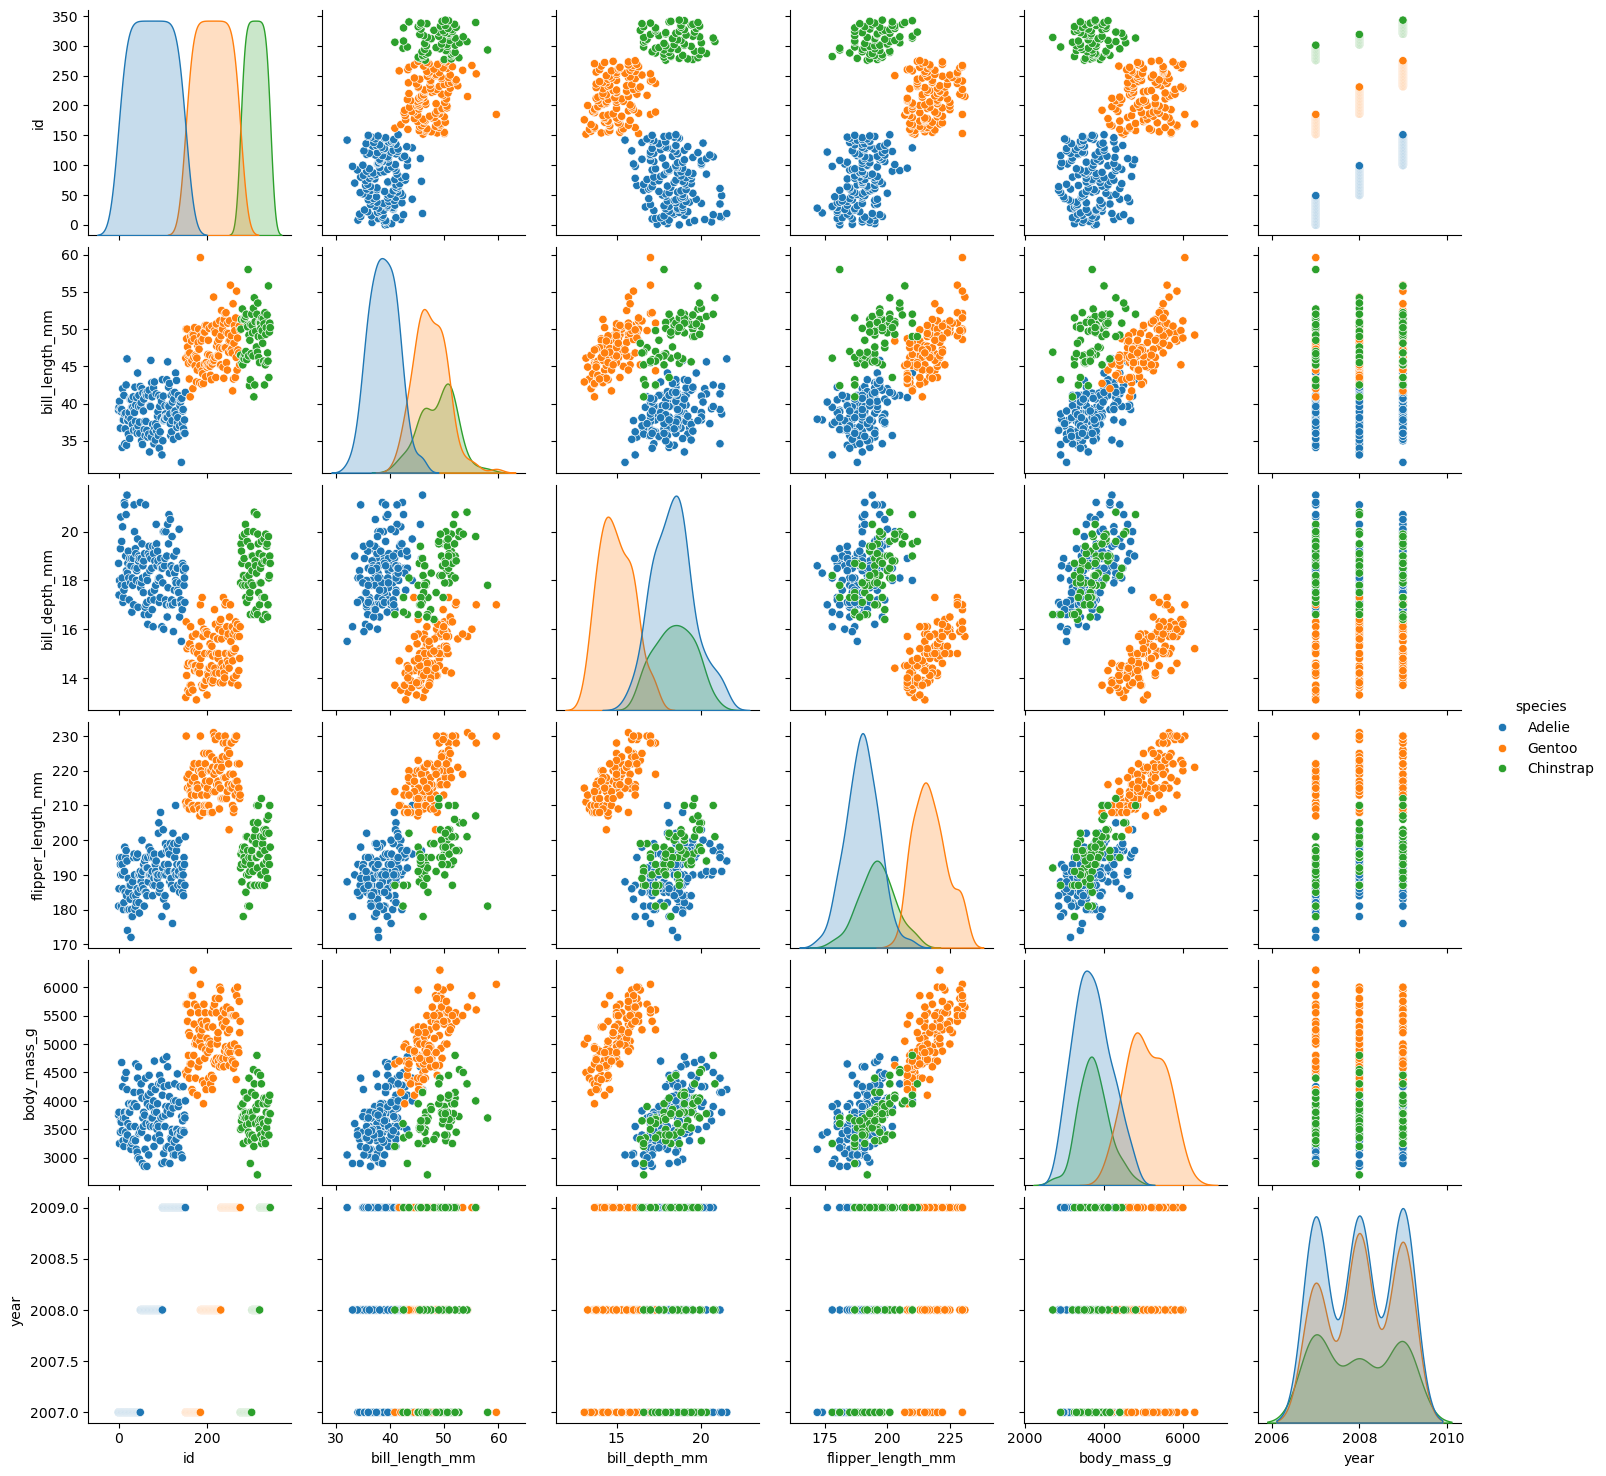

In [333]:
sns.pairplot(p_data, hue='species')
plt.show()

## Distribution of data by Species

Text(0.5, 1.0, 'Body Mass Distribution by Species')

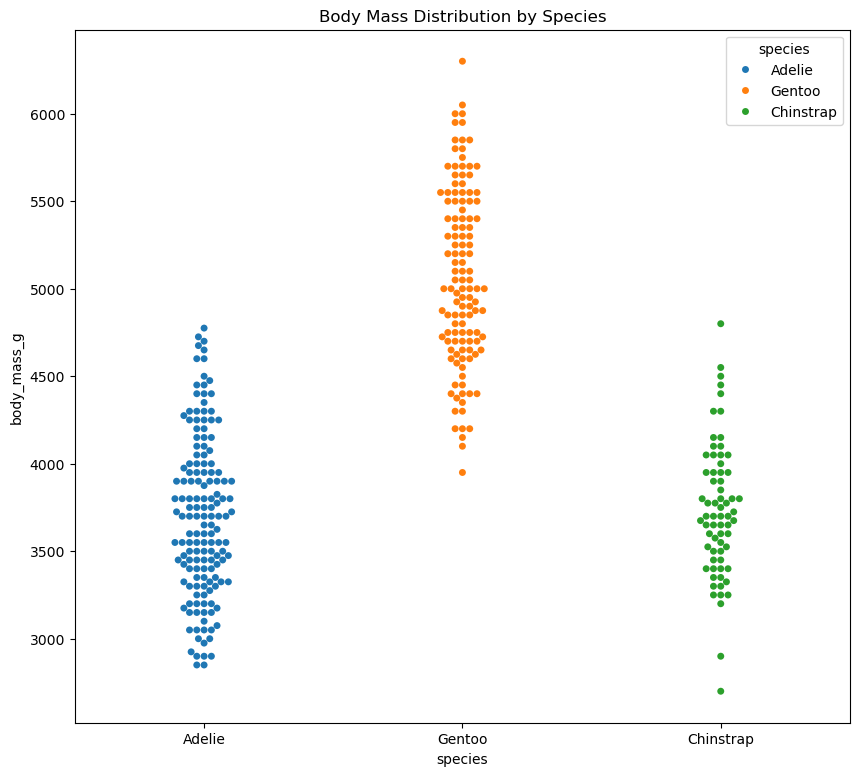

In [334]:
plt.figure(figsize=(10,9))
sns.swarmplot(
    data=p_data, 
    x='species', 
    y='body_mass_g',
    hue='species',
    legend=True)
plt.title('Body Mass Distribution by Species')

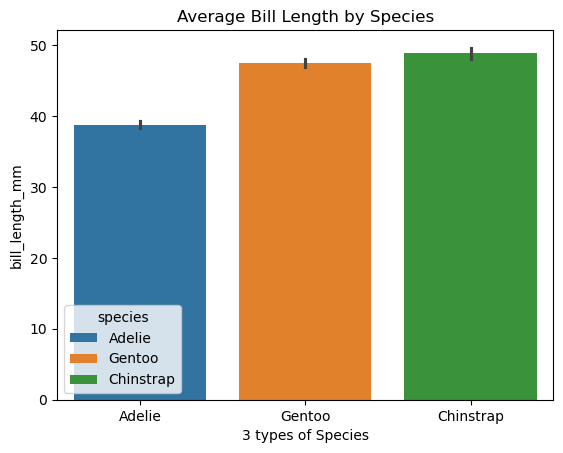

<Figure size 1000x900 with 0 Axes>

In [335]:
sns.barplot(
    data=p_data,
    x='species',
    y='bill_length_mm',
    hue='species',
    legend=True)
plt.xlabel('3 types of Species')
plt.title('Average Bill Length by Species')
plt.figure(figsize=(10,9))
plt.show()

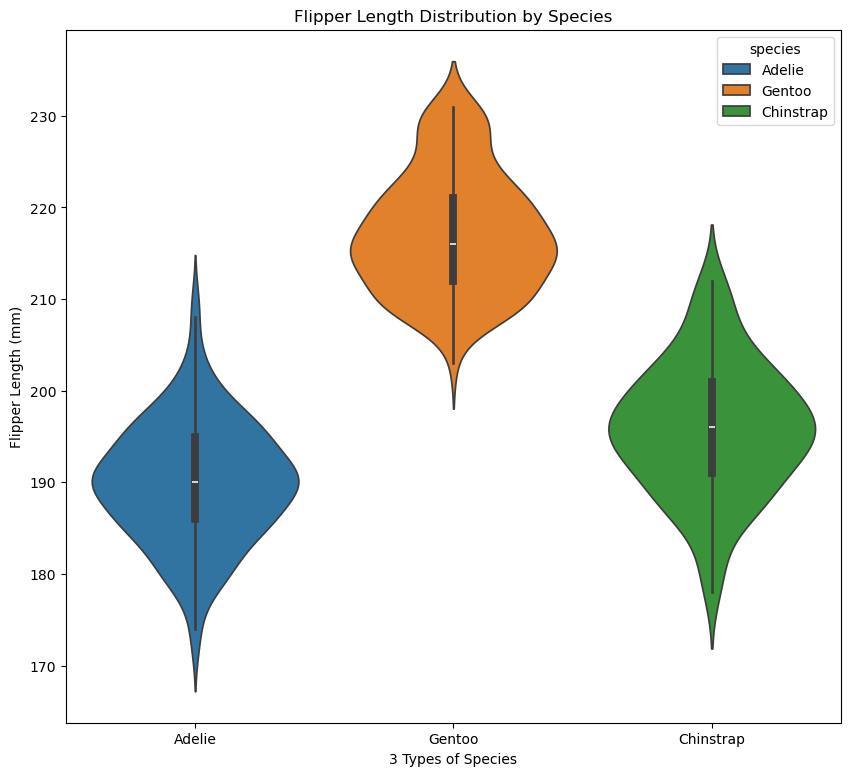

In [336]:
plt.figure(figsize=(10,9))
sns.violinplot(
    data=p_data,
    x='species', 
    y='flipper_length_mm',
    hue='species',
    legend=True)
    
plt.xlabel('3 Types of Species')
plt.ylabel('Flipper Length (mm)')
plt.title('Flipper Length Distribution by Species')
plt.show()




Text(0.5, 1.0, 'Flipper Length vs Body Mass')

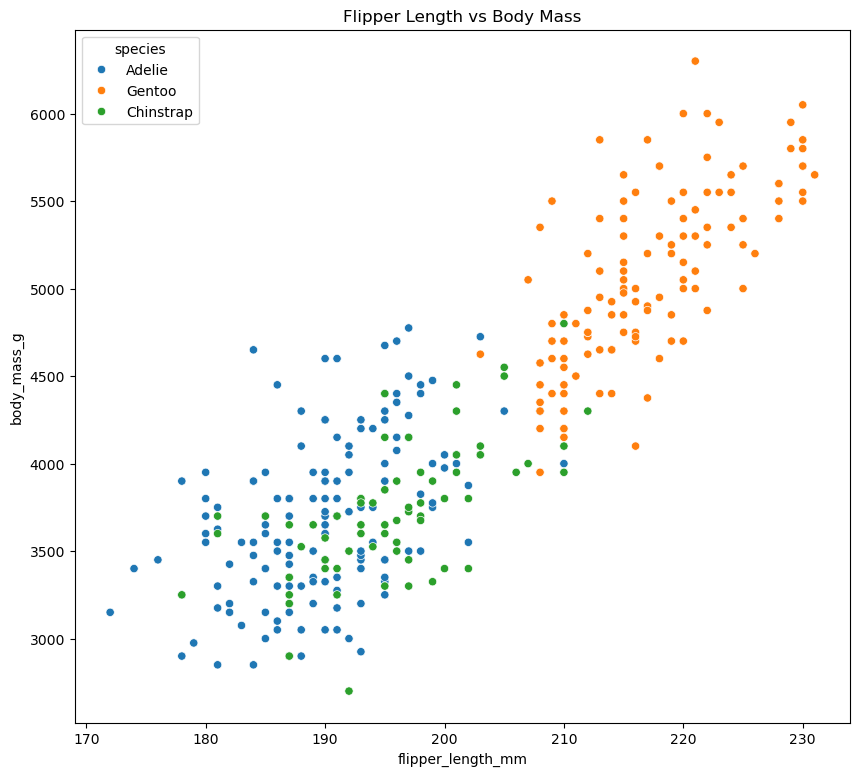

In [337]:
plt.figure(figsize=(10,9))
sns.scatterplot(
    data=p_data,
    x='flipper_length_mm',
    y='body_mass_g', 
    hue='species')
plt.title('Flipper Length vs Body Mass')

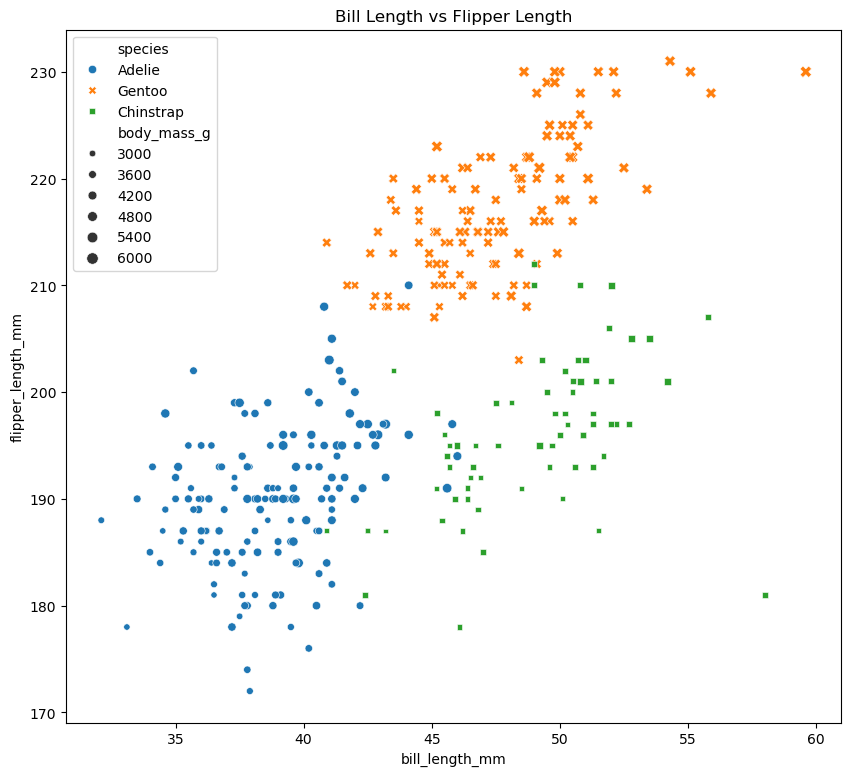

In [338]:
plt.figure(figsize=(10,9))
sns.scatterplot(
    data=p_data,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='species',
    style= 'species',
    size='body_mass_g'
)
plt.title('Bill Length vs Flipper Length')
plt.show()

### Part 02  || Passengers Data

In [339]:
F_data = pd.read_csv("AirPassengers.csv")
F_data.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [340]:
F_data.rename(columns={"#Passengers": "Passengers"}, inplace=True)


In [341]:
F_data.info

<bound method DataFrame.info of        Month  Passengers
0    1949-01         112
1    1949-02         118
2    1949-03         132
3    1949-04         129
4    1949-05         121
..       ...         ...
139  1960-08         606
140  1960-09         508
141  1960-10         461
142  1960-11         390
143  1960-12         432

[144 rows x 2 columns]>

In [342]:
F_data['Month'] = pd.to_datetime(F_data['Month'])
F_data['Year'] = F_data['Month'].dt.year
F_data['Month'] = F_data['Month'].dt.month_name()

In [343]:
F_data.columns

Index(['Month', 'Passengers', 'Year'], dtype='object')

In [344]:
F_data.head()

,Month,Passengers,Year
0,January,112,1949
1,February,118,1949
2,March,132,1949
3,April,129,1949
4,May,121,1949


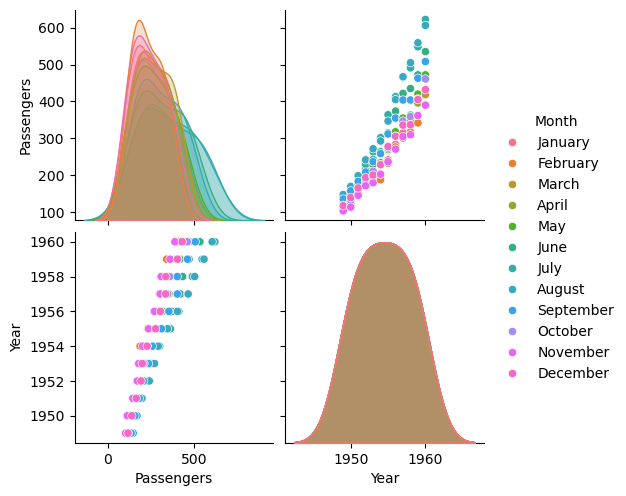

In [345]:
sns.pairplot(F_data,hue='Month')
plt.show()

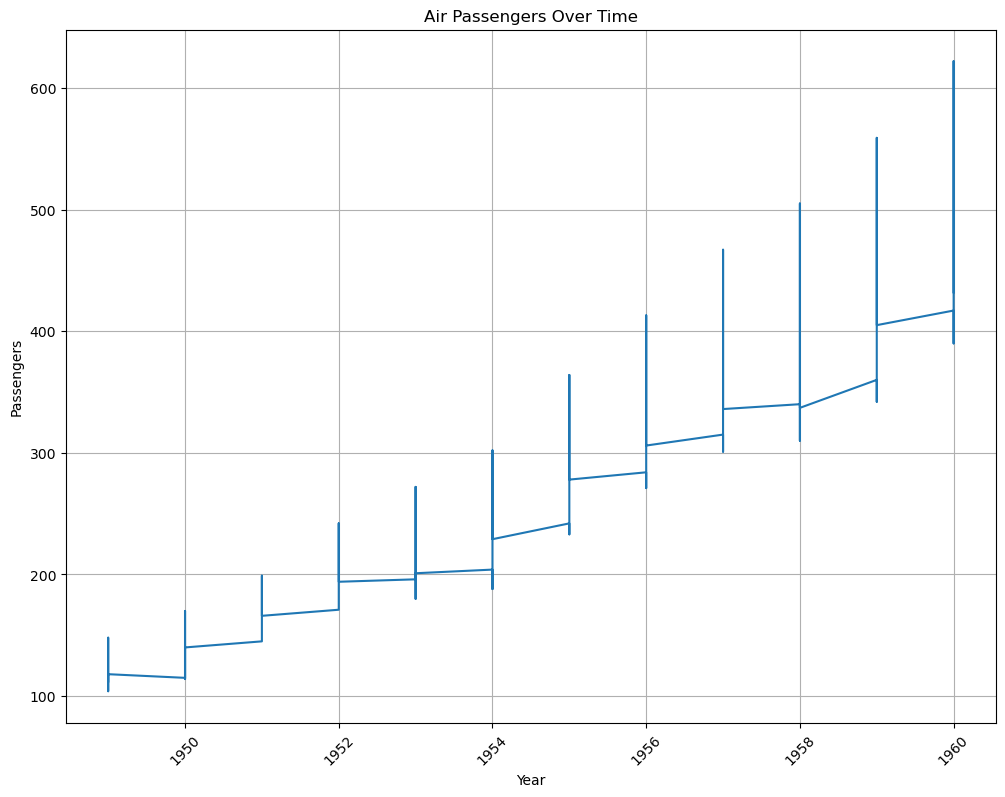

In [346]:
plt.figure(figsize=(12,9))
plt.plot(F_data["Year"], F_data["Passengers"])
plt.xlabel("Year")
plt.xticks(rotation=45)
plt.ylabel("Passengers")
plt.grid()
plt.title("Air Passengers Over Time")
plt.show()

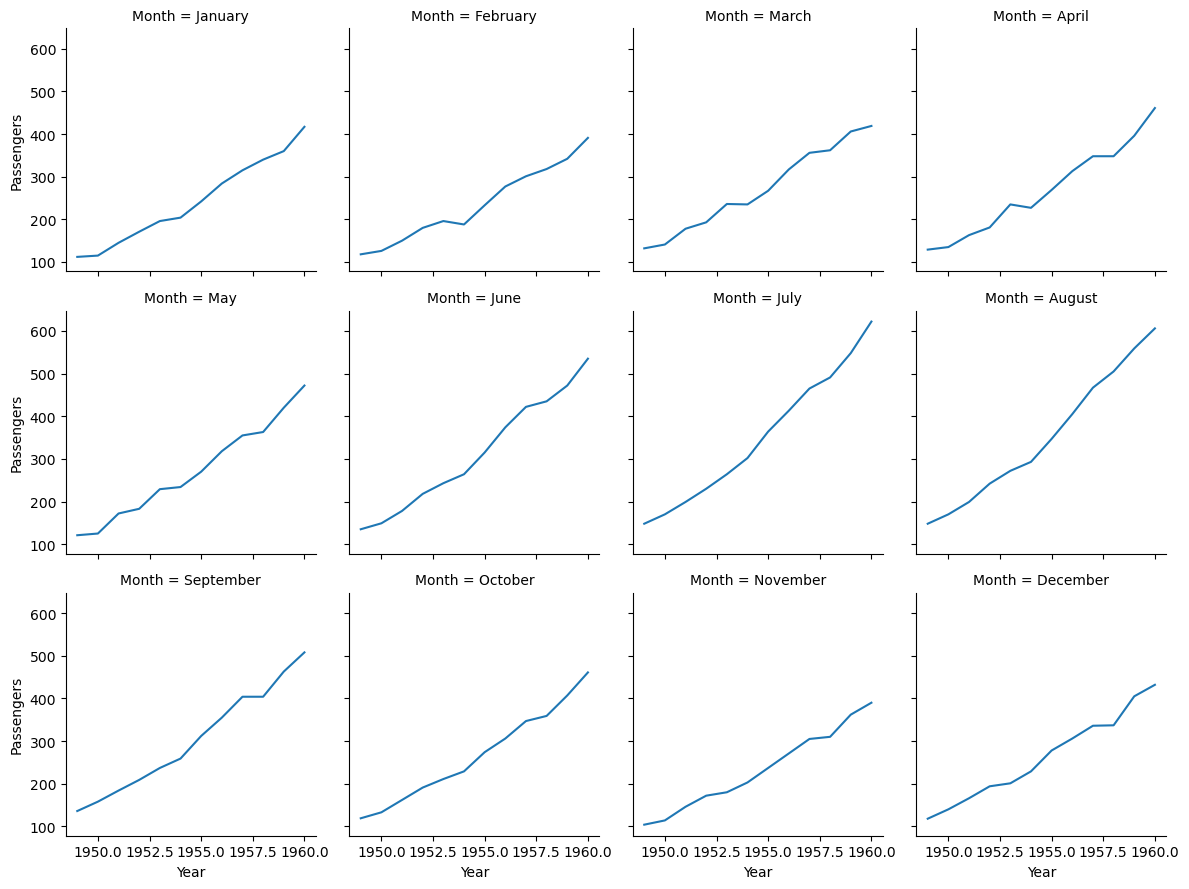

In [347]:
sns.relplot(data=F_data, x="Year", y="Passengers", col="Month", col_wrap=4, kind="line", height=3)

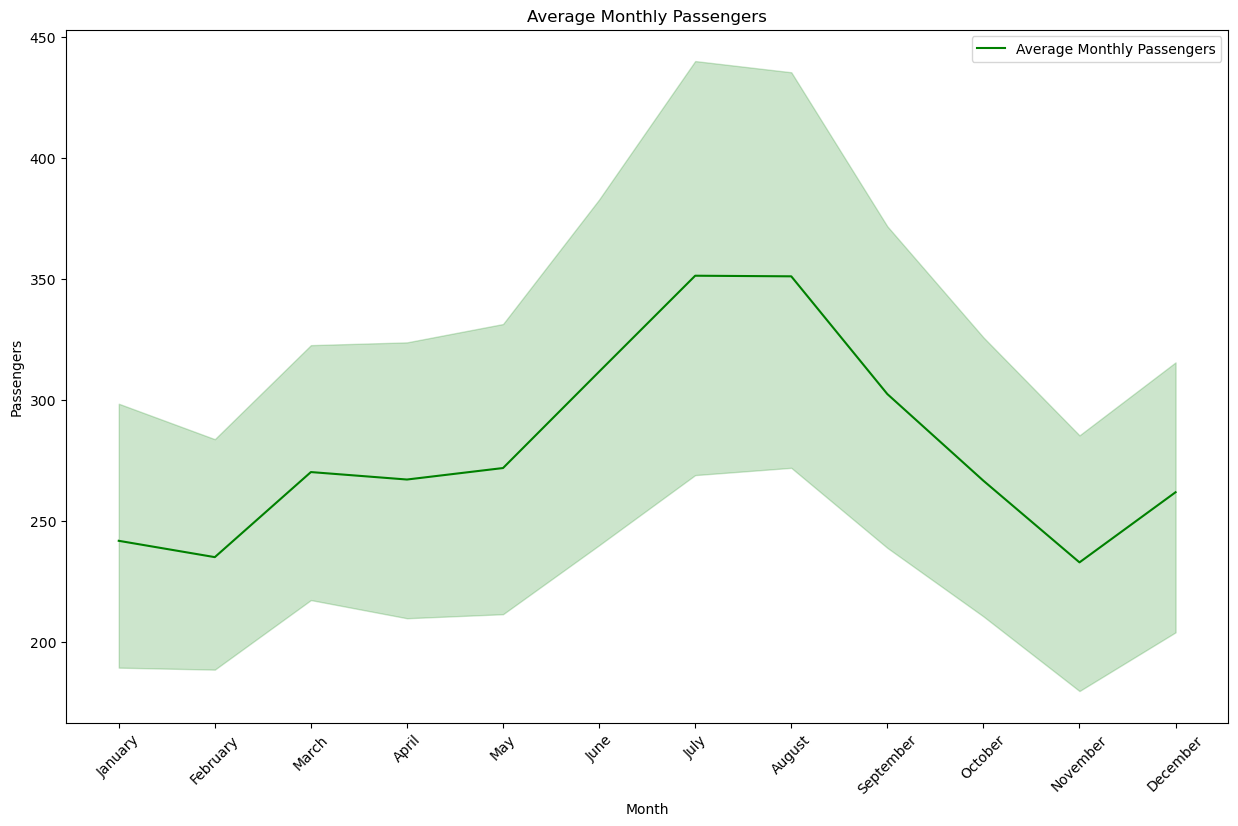

In [348]:
plt.figure(figsize=(15,9))
sns.lineplot(
    data=F_data,
    y="Passengers",
    x="Month",
    estimator="mean",
    label="Average Monthly Passengers",
    color="green"
    
)
plt.xticks(rotation=45)
plt.title("Average Monthly Passengers")
plt.show()


In [349]:
pivot_data = F_data.pivot(
    index="Year",
    columns="Month",
    values="Passengers")
pivot_data.head(12)


Month,April,August,December,February,January,July,June,March,May,November,October,September
Year,,,,,,,,,,,,
1949,129,148,118,118,112,148,135,132,121,104,119,136
1950,135,170,140,126,115,170,149,141,125,114,133,158
1951,163,199,166,150,145,199,178,178,172,146,162,184
1952,181,242,194,180,171,230,218,193,183,172,191,209
1953,235,272,201,196,196,264,243,236,229,180,211,237
1954,227,293,229,188,204,302,264,235,234,203,229,259
1955,269,347,278,233,242,364,315,267,270,237,274,312
1956,313,405,306,277,284,413,374,317,318,271,306,355
1957,348,467,336,301,315,465,422,356,355,305,347,404


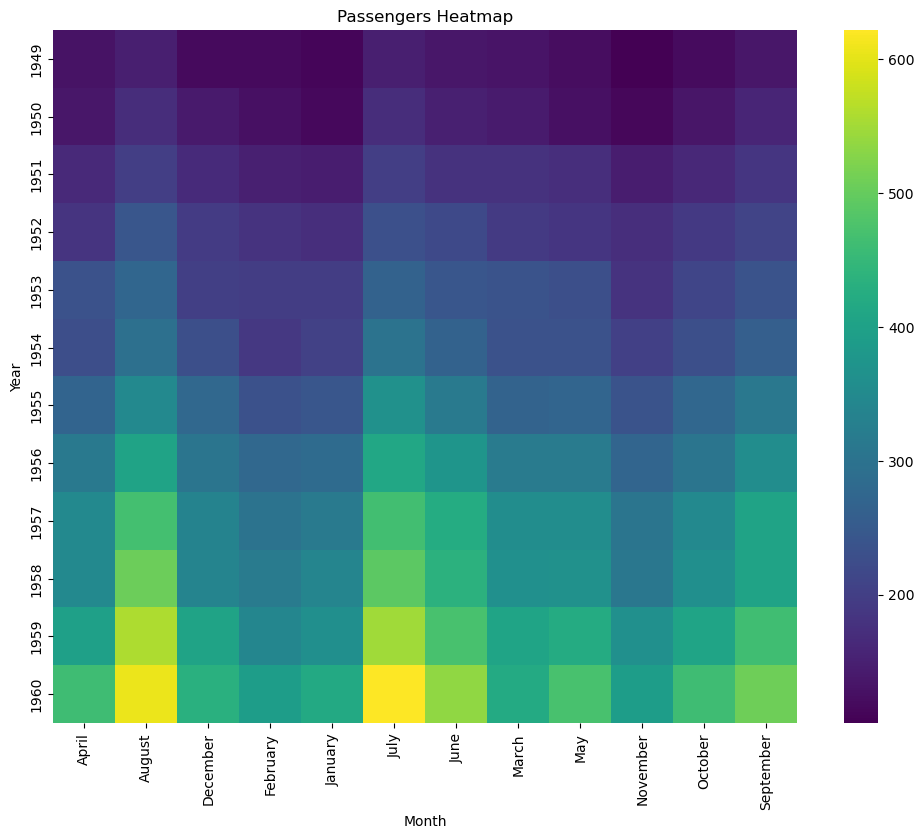

In [350]:
plt.figure(figsize=(12,9))
sns.heatmap(pivot_data, cmap="viridis")
plt.xlabel("Month")
plt.ylabel("Year")
plt.title("Passengers Heatmap")
plt.show()

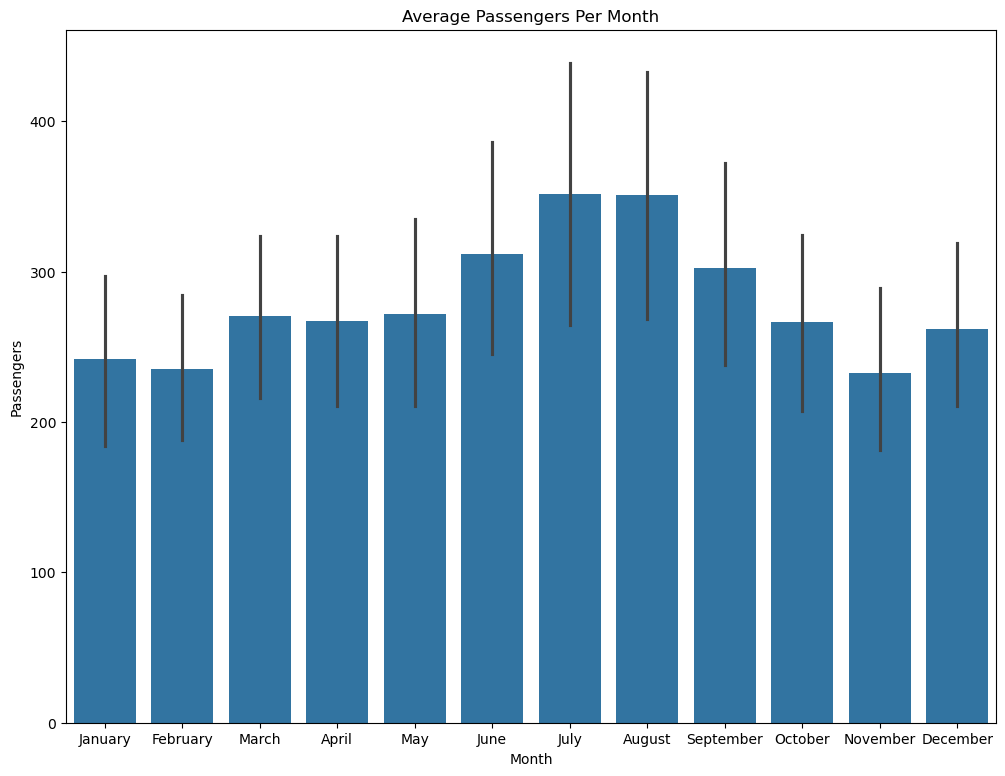

In [351]:
plt.figure(figsize=(12,9))
sns.barplot(data=F_data, x="Month", y="Passengers", estimator="mean")
plt.title("Average Passengers Per Month")
plt.show()


# Using Seaborn’s statistical visualization tools, the Flights dataset was analyzed to identify trends and seasonal patterns. Line plots revealed a steady increase in air passengers over time, indicating long-term growth. Heatmaps highlighted strong seasonal behavior, with peak passenger traffic occurring during summer months. Bar and box plots further confirmed monthly variations and passenger distribution patterns.
